iris dataset is a builtin dataset which contain 150 flower sample including sepal lenght,sepal  width, petal lenght amd petal width

In [1]:
import pandas as pd
from sklearn.datasets import load_iris
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


this is an unsupervised clustering problem, the species labels should not be used to form the clusters. We will use only the four numerical flower measurements to identify groups of similar flowers.
we created the DataFrame using iris.data

In [2]:
print(df.columns)
print("Dataset shape:", df.shape)

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)'],
      dtype='object')
Dataset shape: (150, 4)


In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

print("Preprocessing completed successfully.")

Preprocessing completed successfully.


K means clustering

K Means clustering is an unsupervised machine learning algorithm which is used to cluster data in a defined number of groups. The algorithm involves dividing the data items to their nearest cluster center and then iterating until the clusters become stable.

The key steps are

Define number of clusters (k).
Define initial cluster centers.
Cluster items based on their nearest center.
Define new cluster centers based on clustered items.
Iterate until cluster centers become stable.

it is suitable for the dataset because this can be compared using distance calculations. 
The algorithm can group flowers with similar sepal and petal measurements into clusters.

In [6]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)
print(kmeans_labels)



[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


d:\Users\alwin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [7]:
import pandas as pd
from sklearn.decomposition import PCA

cluster_counts = pd.Series(kmeans_labels).value_counts().sort_index()
print("Number of flowers in each cluster:")
print(cluster_counts)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print("Original number of features:", X_scaled.shape[1])
print("Features after PCA:", X_pca.shape[1])

Number of flowers in each cluster:
0    53
1    50
2    47
Name: count, dtype: int64
Original number of features: 4
Features after PCA: 2


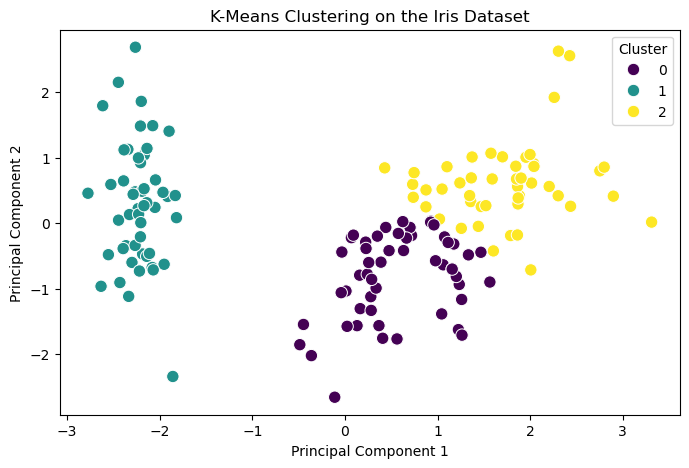

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=kmeans_labels,
    palette="viridis",
    s=80
)

plt.title("K-Means Clustering on the Iris Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

Hierarchical Clustering

Hierarchical Clustering is an unsupervised machine learning method that partitions similar objects into clusters by creating hierarchies of objects.

Hierarchical clustering can be categorized into 2

Agglomerative Clustering: This method initializes each data point to form a cluster and then iteratively combines the clusters.
Divisive Clustering: the process starts with the entire dataset forming one cluster which gets divided into multiple clusters through iteration.



it is suitable for the Iris dataset because it groups flowers based on similarities in their numerical measurements. The algorithm can reveal relationships between flowers and show how groups form at different levels.


In [9]:
from sklearn.cluster import AgglomerativeClustering
hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward" )
hierarchical_labels = hierarchical.fit_predict(X_scaled)

print(hierarchical_labels)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 2 1 1 1 1 1 1 1 1 0 0 0 2 0 2 0 2 0 2 2 0 2 0 2 0 2 2 2 2 0 0 0 0
 0 0 0 0 0 2 2 2 2 0 2 0 0 2 2 2 2 0 2 2 2 2 2 0 2 2 0 0 0 0 0 0 2 0 0 0 0
 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]


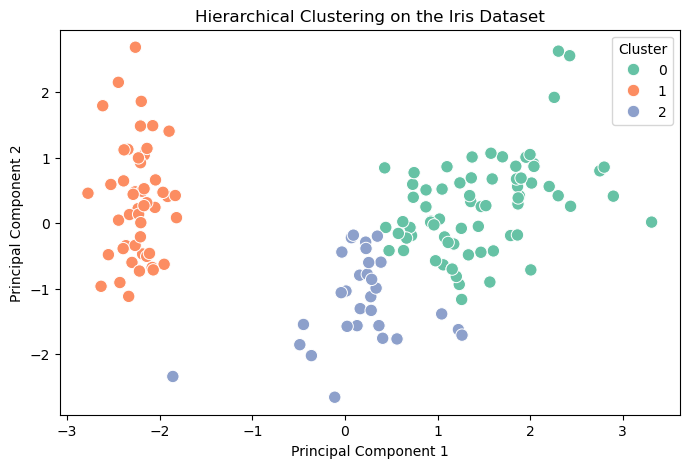

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=hierarchical_labels,
    palette="Set2",
    s=80
)

plt.title("Hierarchical Clustering on the Iris Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()